# Data Mining Lab Assignment 2
## Book Recommendation using a Medallion Data Lake

Name: Lakshya Prajapati
Roll No: LCS2023017

Objective: Build a book recommender using the Bronze, Silver and Gold layers.

## 1. Bronze layer
Read the source CSVs as text to preserve ISBNs and raw values. Add the ingestion time and save the tables without cleaning.

In [1]:
from pathlib import Path
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from zipfile import ZipFile, is_zipfile, BadZipFile
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.sparse import csr_matrix, save_npz, load_npz
from sklearn.neighbors import NearestNeighbors

for folder in ['raw', 'bronze', 'silver', 'gold']:
    Path(folder).mkdir(exist_ok=True)

files = {'users': 'BX-Users.csv', 'books': 'BX-Books.csv',
         'ratings': 'BX-Book-Ratings.csv'}

urls = [
    'https://cdn.freecodecamp.org/project-data/books/book-crossings.zip',
    'https://raw.githubusercontent.com/freeCodeCamp/cdn/main/build/project-data/books/book-crossings.zip',
    'https://raw.githubusercontent.com/XuefengHuang/RecommendationSystem/master/BX-CSV-Dump.zip'
]
zip_path = Path('raw/book-crossings.zip')


def valid_archive(path):
    try:
        if not is_zipfile(path):
            return False
        with ZipFile(path) as archive:
            names = {Path(name).name for name in archive.namelist()}
            return set(files.values()).issubset(names) and archive.testzip() is None
    except (BadZipFile, OSError, RuntimeError):
        return False


if not valid_archive(zip_path):
    session = requests.Session()
    session.headers.update({'User-Agent': 'Mozilla/5.0'})
    session.mount('https://', HTTPAdapter(max_retries=Retry(
        total=1, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504])))
    temp = zip_path.with_suffix('.part')
    for url in urls:
        try:
            with session.get(url, stream=True, timeout=(10, 45)) as response:
                response.raise_for_status()
                with temp.open('wb') as out:
                    for chunk in response.iter_content(chunk_size=1024 * 1024):
                        out.write(chunk)
            if not valid_archive(temp):
                raise ValueError('Invalid or incomplete dataset archive')
            temp.replace(zip_path)
            print('Dataset downloaded from:', url)
            break
        except (requests.RequestException, OSError, ValueError) as error:
            print('Download failed:', url, '-', error)
            temp.unlink(missing_ok=True)
    else:
        raise RuntimeError('All dataset sources failed. Check the runtime network and retry.')
else:
    print('Using existing dataset archive.')


Dataset downloaded from: https://cdn.freecodecamp.org/project-data/books/book-crossings.zip


In [2]:
stamp = pd.Timestamp.now(tz='UTC')
with ZipFile(zip_path) as archive:
    for table, filename in files.items():
        member = next(name for name in archive.namelist()
                      if Path(name).name == filename)
        with archive.open(member) as source:
            # The dataset has escaped quotes in some book fields.
            df = pd.read_csv(source, delimiter=';', encoding='iso-8859-1',
                             escapechar=chr(92), dtype='string', na_filter=False)
        df['ingestion_timestamp'] = stamp
        df.to_parquet(f'bronze/{table}.parquet', index=False)
        print(table, df.shape)
del df

users (278858, 4)
books (271379, 9)
ratings (1149780, 4)


## 2. Exploratory data analysis (EDA)

Check missing values, rating distributions, ages, publication years and matrix sparsity before cleaning.

In [3]:
users_b = pd.read_parquet('bronze/users.parquet')
books_b = pd.read_parquet('bronze/books.parquet')
ratings_b = pd.read_parquet('bronze/ratings.parquet')

# Treat raw NULL and empty fields as missing for analysis only.
def missing_mask(series):
    return series.isna() | series.str.strip().str.lower().isin(['', 'null', 'nan'])

missing_totals = {}
for name, df in [('Users', users_b), ('Books', books_b), ('Ratings', ratings_b)]:
    source_cols = df.columns.drop('ingestion_timestamp')
    missing = pd.Series({c: missing_mask(df[c]).sum() for c in source_cols})
    missing_totals[name] = int(missing.sum())
    print(name, 'shape:', df.shape)
    display(pd.DataFrame({'dtype': df.dtypes, 'missing source values': missing}))
    display(df.head(3))

Users shape: (278858, 4)


,dtype,missing source values
Age,string[python],110762.0
Location,string[python],0.0
User-ID,string[python],0.0
ingestion_timestamp,"datetime64[us, UTC]",NaN


,User-ID,Location,Age,ingestion_timestamp
0,1,"nyc, new york, usa",NULL,2026-11-26 14:53:32.650408+00:00
1,2,"stockton, california, usa",18,2026-11-26 14:53:32.650408+00:00
2,3,"moscow, yukon territory, russia",NULL,2026-11-26 14:53:32.650408+00:00


Books shape: (271379, 9)


,dtype,missing source values
Book-Author,string[python],0.0
Book-Title,string[python],0.0
ISBN,string[python],0.0
Image-URL-L,string[python],0.0
Image-URL-M,string[python],0.0
Image-URL-S,string[python],0.0
Publisher,string[python],0.0
Year-Of-Publication,string[python],0.0
ingestion_timestamp,"datetime64[us, UTC]",NaN


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L,ingestion_timestamp
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,2026-11-26 14:53:32.650408+00:00
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,2026-11-26 14:53:32.650408+00:00
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,2026-11-26 14:53:32.650408+00:00


Ratings shape: (1149780, 4)


,dtype,missing source values
Book-Rating,string[python],0.0
ISBN,string[python],0.0
User-ID,string[python],0.0
ingestion_timestamp,"datetime64[us, UTC]",NaN


,User-ID,ISBN,Book-Rating,ingestion_timestamp
0,276725,034545104X,0,2026-11-26 14:53:32.650408+00:00
1,276726,0155061224,5,2026-11-26 14:53:32.650408+00:00
2,276727,0446520802,0,2026-11-26 14:53:32.650408+00:00


Rating distribution:


,count
Book-Rating,
0,716109
1,1770
2,2759
3,5996
4,8904
5,50974
6,36924
7,76457
8,103736


Zero ratings: 716109


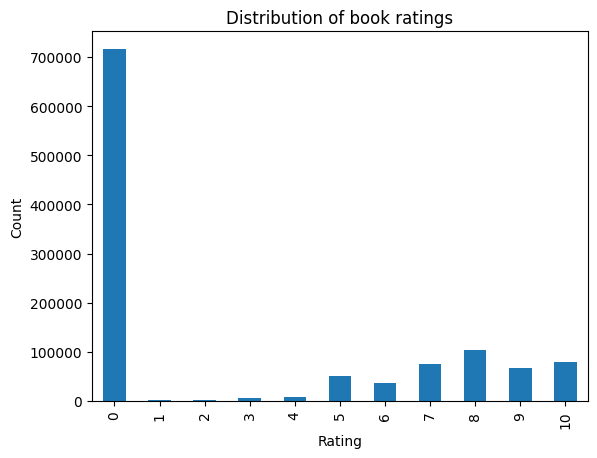

Age statistics:


,Age
count,168096.0
mean,34.751434
std,14.428097
min,0.0
25%,24.0
50%,32.0
75%,44.0
max,244.0


Invalid ages: 1248
Publication year statistics:


,Year-Of-Publication
count,271379.0
mean,1959.75605
std,258.011363
min,0.0
25%,1989.0
50%,1995.0
75%,2000.0
max,2050.0


Invalid publication years: 4630


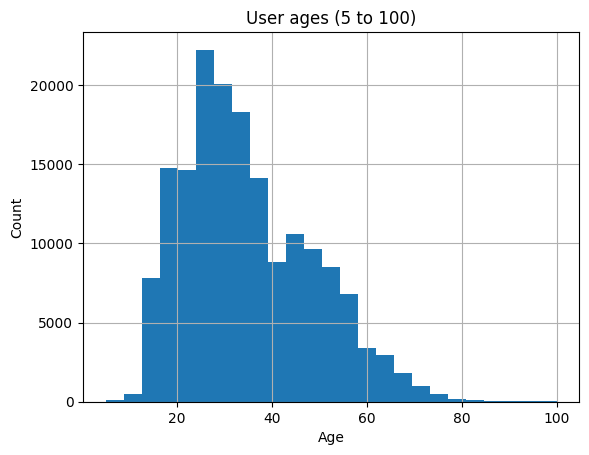

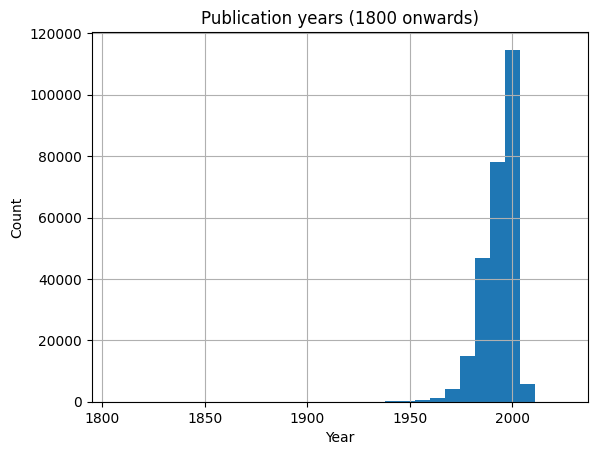

In [4]:
rating_values = pd.to_numeric(ratings_b['Book-Rating'], errors='coerce')
ages = pd.to_numeric(users_b['Age'], errors='coerce')
years = pd.to_numeric(books_b['Year-Of-Publication'], errors='coerce')
current_year = pd.Timestamp.now().year

rating_counts = rating_values.value_counts().sort_index()
print('Rating distribution:')
display(rating_counts)
print('Zero ratings:', int(rating_values.eq(0).sum()))
rating_counts.plot.bar(title='Distribution of book ratings', xlabel='Rating', ylabel='Count')
plt.show()

bad_ages = int(((ages < 5) | (ages > 100)).sum())
bad_years = int(((years <= 0) | (years > current_year)).sum())
print('Age statistics:')
display(ages.describe())
print('Invalid ages:', bad_ages)
print('Publication year statistics:')
display(years.describe())
print('Invalid publication years:', bad_years)

# Plot the normal range so extreme outliers do not hide the distribution.
ages[ages.between(5, 100)].hist(bins=25)
plt.title('User ages (5 to 100)')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()
years[years.between(1800, current_year)].hist(bins=30)
plt.title('Publication years (1800 onwards)')
plt.xlabel('Year')
plt.ylabel('Count')
plt.show()

In [5]:
per_user = ratings_b.groupby('User-ID').size()
per_book = ratings_b.groupby('ISBN').size()
print('Ratings per user and per book (raw):')
display(pd.DataFrame({'per user': per_user.describe(), 'per book': per_book.describe()}))

MIN_RATINGS = 10  # initial candidate
explicit = ratings_b[rating_values.between(1, 10)]
explicit_users = explicit.groupby('User-ID').size()
explicit_books = explicit.groupby('ISBN').size()
print('Users with fewer than 10 explicit ratings:', (explicit_users < MIN_RATINGS).sum())
print('Books with fewer than 10 explicit ratings:', (explicit_books < MIN_RATINGS).sum())

# Only pairs present in the source user and book tables count towards the matrix.
valid = ratings_b['User-ID'].isin(users_b['User-ID'].dropna()) & ratings_b['ISBN'].isin(books_b['ISBN'].dropna())
observed = ratings_b.loc[valid, ['User-ID', 'ISBN']].drop_duplicates().shape[0]
possible = users_b['User-ID'].nunique() * books_b['ISBN'].nunique()
density = 100 * observed / possible
print(f'Possible pairs: {possible:,}')
print(f'Observed pairs (including 0 ratings): {observed:,}')
print(f'Observed percentage (density): {density:.6f}%')
print(f'Empty percentage (sparsity): {100 - density:.6f}%')
explicit_pairs = ratings_b.loc[valid & rating_values.between(1, 10), ['User-ID', 'ISBN']].drop_duplicates()
print(f'Explicit rating density: {100 * len(explicit_pairs) / possible:.6f}%')

Ratings per user and per book (raw):


,per user,per book
count,105283.000000,340556.000000
mean,10.920851,3.376185
std,90.562825,12.436252
min,1.000000,1.000000
25%,1.000000,1.000000
50%,1.000000,1.000000
75%,4.000000,2.000000
max,13602.000000,2502.000000


Users with fewer than 10 explicit ratings: 70471
Books with fewer than 10 explicit ratings: 180328
Possible pairs: 75,676,205,182
Observed pairs (including 0 ratings): 1,031,175
Observed percentage (density): 0.001363%
Empty percentage (sparsity): 99.998637%
Explicit rating density: 0.000507%


### EDA observations and Silver plan

- Source columns are text; convert ages, years and ratings to numeric values and handle missing fields.
- Zero ratings are implicit interactions; retain only explicit ratings for training.
- Ages and publication years outside valid ranges need correction; fill missing ages with the median.
- Low-activity users and books can produce unreliable similarities; compare several minimum counts before filtering.
- The matrix has very few observed pairs compared with all possible pairs; store it in sparse form.

Replace these five observations with the numerical lines printed below after running on the dataset.

In [6]:
# Dataset-specific observations (computed from the actual Bronze files).
notes = [
    f"Users: {users_b.shape}, Books: {books_b.shape}, Ratings: {ratings_b.shape}; source missing counts are {missing_totals}. Source columns are strings; convert numbers in Silver.",
    f"Zero ratings: {rating_values.eq(0).sum():,} ({100 * rating_values.eq(0).mean():.2f}%); keep only 1–10 for training.",
    f"There are {bad_ages:,} invalid ages and {bad_years:,} invalid publication years; null them and use median imputation for age.",
    f"Median raw ratings per user/book: {per_user.median():g}/{per_book.median():g}; {(explicit_users < MIN_RATINGS).sum():,} users and {(explicit_books < MIN_RATINGS).sum():,} books have fewer than 10 explicit ratings, so compare activity thresholds in Silver.",
    f"Only {density:.6f}% of possible pairs have a record; use a sparse matrix after Silver filtering."
]
print('\n'.join('- ' + line for line in notes))

- Users: (278858, 4), Books: (271379, 9), Ratings: (1149780, 4); source missing counts are {'Users': 110762, 'Books': 0, 'Ratings': 0}. Source columns are strings; convert numbers in Silver.
- Zero ratings: 716,109 (62.28%); keep only 1–10 for training.
- There are 1,248 invalid ages and 4,630 invalid publication years; null them and use median imputation for age.
- Median raw ratings per user/book: 1/1; 70,471 users and 180,328 books have fewer than 10 explicit ratings, so compare activity thresholds in Silver.
- Only 0.001363% of possible pairs have a record; use a sparse matrix after Silver filtering.


## 3. Silver layer
Clean the source tables, keep valid user-book pairs and separate explicit ratings from reading history. Compare activity thresholds on the cleaned data before saving.

In [7]:
def start_cleaning(df):
    # Keep the raw Bronze files unchanged.
    return df.drop(columns='ingestion_timestamp').drop_duplicates().copy()

def clean_text(series):
    result = series.str.replace(r'\s+', ' ', regex=True).str.strip()
    return result.mask(result.str.lower().isin(['', 'null', 'nan']))

users = start_cleaning(users_b).rename(columns={'User-ID': 'user_id', 'Location': 'location', 'Age': 'age'})
users['user_id'] = pd.to_numeric(users['user_id'], errors='coerce')
users = users[users['user_id'].gt(0) & users['user_id'].mod(1).eq(0)]
users = users.dropna(subset=['user_id']).drop_duplicates('user_id')
users['user_id'] = users['user_id'].astype('int64')
users['age'] = pd.to_numeric(users['age'], errors='coerce').astype('float64')
users['age'] = users['age'].where(users['age'].between(5, 100))
median_age = users['age'].median()
users['age'] = users['age'].fillna(median_age)

location = clean_text(users['location']).str.lower().str.split(',')
users['country'] = clean_text(location.str[-1])
users['state'] = clean_text(location.str[-2])
users['city'] = clean_text(location.str[:-2].str.join(','))
users = users.drop(columns='location')
print('Median age used:', median_age)
display(users.head())

Median age used: 32.0


,user_id,age,country,state,city
0,1,32.0,usa,new york,nyc
1,2,18.0,usa,california,stockton
2,3,32.0,russia,yukon territory,moscow
3,4,17.0,portugal,v.n.gaia,porto
4,5,32.0,united kingdom,hants,farnborough


In [8]:
books = start_cleaning(books_b).rename(columns={
    'ISBN': 'isbn', 'Book-Title': 'title', 'Book-Author': 'author',
    'Year-Of-Publication': 'year', 'Publisher': 'publisher'
})
books = books.drop(columns=[c for c in books.columns if c.startswith('Image-URL')])
books['isbn'] = clean_text(books['isbn']).str.upper()
for col in ['title', 'author', 'publisher']:
    books[col] = clean_text(books[col])
# Keep display text as written; standardise matching separately.
books['publisher'] = books['publisher'].str.lower()
books['year'] = pd.to_numeric(books['year'], errors='coerce')
books['year'] = books['year'].where(books['year'].between(1, current_year) & (books['year'] % 1 == 0)).astype('Int64')
books = books.dropna(subset=['isbn', 'title']).drop_duplicates('isbn')
display(books.head())
# Match editions by title and author, not by ISBN alone.
def match_key(series):
    return series.fillna('').str.normalize('NFKC').str.casefold().str.replace(r'\s+', ' ', regex=True).str.strip()

books['title_key'] = match_key(books['title'])
books['work_key'] = books['title_key'] + ' | ' + match_key(books['author'])

,isbn,title,author,year,publisher
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,oxford university press
1,0002005018,Clara Callan,Richard Bruce Wright,2001,harperflamingo canada
2,0060973129,Decision in Normandy,Carlo D'Este,1991,harperperennial
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,farrar straus giroux
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,w. w. norton &amp; company


In [9]:
ratings = start_cleaning(ratings_b).rename(columns={
    'User-ID': 'user_id', 'ISBN': 'isbn', 'Book-Rating': 'rating'
})
ratings['user_id'] = pd.to_numeric(ratings['user_id'], errors='coerce')
ratings['isbn'] = clean_text(ratings['isbn']).str.upper()
ratings['rating'] = pd.to_numeric(ratings['rating'], errors='coerce')
ratings = ratings.dropna(subset=['user_id', 'isbn', 'rating'])
ratings = ratings[ratings['rating'].between(0, 10) & ratings['rating'].mod(1).eq(0)
                  & ratings['user_id'].gt(0) & ratings['user_id'].mod(1).eq(0)].copy()
ratings['user_id'] = ratings['user_id'].astype('int64')
ratings = ratings[ratings['user_id'].isin(users['user_id']) & ratings['isbn'].isin(books['isbn'])]
ratings = ratings.drop_duplicates()

# Keep IDs of all known books, including implicit (zero) ratings, for exclusion later.
# No zero scores are included in the cleaned ratings table.
reading_history = ratings[['user_id', 'isbn']].drop_duplicates()
reading_history = reading_history.merge(books[['isbn', 'title', 'work_key']], on='isbn')
ratings = ratings[ratings['rating'].between(1, 10)]
# One rating per user-book pair; average if conflicting ratings exist.
ratings = ratings.groupby(['user_id', 'isbn'], as_index=False)['rating'].mean()
print('Explicit ratings before activity filtering:', len(ratings))



Explicit ratings before activity filtering: 383853


In [10]:
def filter_activity(data, minimum):
    filtered = data
    while True:
        counts = filtered['user_id'].value_counts()
        next_data = filtered[filtered['user_id'].isin(counts[counts >= minimum].index)]
        counts = next_data['isbn'].value_counts()
        next_data = next_data[next_data['isbn'].isin(counts[counts >= minimum].index)]
        if len(next_data) == len(filtered):
            return next_data
        filtered = next_data

candidates = {}
summary = []
for minimum in [5, 10, 15]:
    subset = filter_activity(ratings, minimum)
    candidates[minimum] = subset
    summary.append({'minimum': minimum, 'users': subset.user_id.nunique(),
                    'books': subset.isbn.nunique(), 'ratings': len(subset),
                    'retained (%)': round(100 * len(subset) / len(ratings), 2)})
display(pd.DataFrame(summary))

# Prefer 10 if the remaining catalog and user pool are large enough.
MIN_RATINGS = 10 if (candidates[10].isbn.nunique() >= 100 and
                     candidates[10].user_id.nunique() >= 3) else 5
ratings = candidates[MIN_RATINGS]
print(f'Chosen minimum: {MIN_RATINGS}; {ratings.isbn.nunique():,} books and '
      f'{ratings.user_id.nunique():,} users remain.')
print('This removes low-activity entries while keeping a useful catalog.')
del candidates

,minimum,users,books,ratings,retained (%)
0,5,6858,9092,115332,30.05
1,10,1820,2030,41469,10.80
2,15,0,0,0,0.00


Chosen minimum: 10; 2,030 books and 1,820 users remain.
This removes low-activity entries while keeping a useful catalog.


A minimum of 10 is preferred to reduce similarities based on very few ratings. If it leaves fewer than 100 books or 3 users, use 5 instead. The comparison above shows the trade-off between rating support and catalog size.

In [11]:
users = users[users['user_id'].isin(ratings['user_id'])].copy()
books = books[books['isbn'].isin(ratings['isbn'])].copy()
reading_history = reading_history[reading_history['user_id'].isin(users['user_id'])]

assert not ratings.empty, 'No ratings remain; review the threshold.'
assert ratings['rating'].between(1, 10).all()
assert ratings.groupby('user_id').size().min() >= MIN_RATINGS
assert ratings.groupby('isbn').size().min() >= MIN_RATINGS
assert not ratings.duplicated(['user_id', 'isbn']).any()
assert ratings['user_id'].isin(users['user_id']).all()
assert ratings['isbn'].isin(books['isbn']).all()

for name, df in [('users', users), ('books', books), ('ratings', ratings), ('reading_history', reading_history)]:
    df.to_parquet(f'silver/{name}.parquet', index=False)
    print(name, df.shape)

users (1820, 5)
books (2030, 7)
ratings (41469, 3)
reading_history (478415, 4)


## 4. Gold layer

Create the sparse user-book matrix, save the book and user lookups, and calculate average ratings and rating counts.

In [12]:
ratings = pd.read_parquet('silver/ratings.parquet')
books = pd.read_parquet('silver/books.parquet')
reading_history = pd.read_parquet('silver/reading_history.parquet')

user_lookup = pd.DataFrame({'user_id': sorted(ratings['user_id'].unique())})
user_lookup['user_index'] = np.arange(len(user_lookup))
book_lookup = books[['isbn', 'title', 'author', 'title_key', 'work_key']].sort_values('isbn').reset_index(drop=True)
book_lookup['book_index'] = np.arange(len(book_lookup))

user_map = dict(zip(user_lookup['user_id'], user_lookup['user_index']))
book_map = dict(zip(book_lookup['isbn'], book_lookup['book_index']))

row = ratings['user_id'].map(user_map).to_numpy(dtype=int)
col = ratings['isbn'].map(book_map).to_numpy(dtype=int)
values = ratings['rating'].to_numpy(dtype=np.float32)
user_book_matrix = csr_matrix((values, (row, col)), shape=(len(user_lookup), len(book_lookup)))

save_npz('gold/user_book_matrix.npz', user_book_matrix)
user_lookup.to_parquet('gold/user_lookup.parquet', index=False)
book_lookup.to_parquet('gold/book_lookup.parquet', index=False)
reading_history.to_parquet('gold/reading_history.parquet', index=False)

for key, name in [('user_id', 'user_stats'), ('isbn', 'book_stats')]:
    stats = ratings.groupby(key)['rating'].agg(avg_rating='mean', rating_count='size').reset_index()
    stats.to_parquet(f'gold/{name}.parquet', index=False)
    print(name)
    display(stats.head())

assert user_book_matrix.nnz == len(ratings)
print('Matrix shape (users x books):', user_book_matrix.shape)
print('Stored ratings:', user_book_matrix.nnz)
print('Matrix sparsity:', round(100 * (1 - user_book_matrix.nnz / np.prod(user_book_matrix.shape)), 4), '%')

user_stats


,user_id,avg_rating,rating_count
0,243,7.769231,13
1,254,8.45,20
2,638,9.454545,22
3,805,8.4,10
4,882,8.235294,17


book_stats


,isbn,avg_rating,rating_count
0,0020199600,8.166667,12
1,0020442203,8.833333,12
2,002542730X,7.481481,27
3,0028604199,7.9,10
4,0060002050,7.545455,11


Matrix shape (users x books): (1820, 2030)
Stored ratings: 41469
Matrix sparsity: 98.8776 %


## 5. Item-based collaborative filtering

Transpose the matrix to get books as rows. Use KNN with cosine distance to find similar books (`similarity = 1 - distance`).

In [13]:
user_book_matrix = load_npz('gold/user_book_matrix.npz').tocsr()
book_matrix = user_book_matrix.T.tocsr()
book_lookup = pd.read_parquet('gold/book_lookup.parquet').sort_values('book_index').reset_index(drop=True)
user_lookup = pd.read_parquet('gold/user_lookup.parquet').sort_values('user_index')
book_stats = pd.read_parquet('gold/book_stats.parquet')
history = pd.read_parquet('gold/reading_history.parquet')
user_map = dict(zip(user_lookup['user_id'], user_lookup['user_index']))

# Reuse neighbour results for books liked by more than one user.
def fit_neighbors(matrix):
    items = matrix.T.tocsr()
    knn = NearestNeighbors(metric='cosine', algorithm='brute').fit(items)

    @lru_cache(maxsize=2048)
    def find(index, k):
        count = min(k + 1, items.shape[0])
        distances, indices = knn.kneighbors(items[index], n_neighbors=count)
        return tuple((int(i), float(1 - d)) for i, d in zip(indices[0], distances[0])
                     if i != index and d < 1)
    return find

neighbors = fit_neighbors(user_book_matrix)

def similar_books(title, n=10):
    columns = ['title', 'author', 'similarity']
    key = match_key(pd.Series([title], dtype='string')).iloc[0]
    matches = book_lookup[book_lookup.title_key.eq(key)]
    if matches.empty or n <= 0:
        return pd.DataFrame(columns=columns)
    matches = matches.merge(book_stats[['isbn', 'rating_count']], on='isbn')
    index = int(matches.sort_values('rating_count', ascending=False).iloc[0].book_index)
    seen = {book_lookup.at[index, 'work_key']}
    result = []
    for i, similarity in neighbors(index, len(book_lookup) - 1):
        book = book_lookup.iloc[i]
        if book.work_key in seen:
            continue
        result.append((book.title, book.author, round(similarity, 4)))
        seen.add(book.work_key)
        if len(result) == n:
            break
    return pd.DataFrame(result, columns=columns)

In [14]:
# Example: use a popular title from the actual Gold data.
example_isbn = book_stats.sort_values('rating_count', ascending=False).iloc[0]['isbn']
example_title = book_lookup.loc[book_lookup['isbn'] == example_isbn, 'title'].iloc[0]
print('Similar books to:', example_title)
display(similar_books(example_title))

Similar books to: The Lovely Bones: A Novel


,title,author,similarity
0,Where the Heart Is (Oprah's Book Club (Paperba...,Billie Letts,0.2192
1,Lucky : A Memoir,Alice Sebold,0.2180
2,The Da Vinci Code,Dan Brown,0.1783
3,The Pilot's Wife : A Novel,Anita Shreve,0.1763
4,Good in Bed,Jennifer Weiner,0.1758
5,Nights in Rodanthe,Nicholas Sparks,0.1702
6,The Pact: A Love Story,Jodi Picoult,0.1682
7,The Lake House,James Patterson,0.1662
8,Lucky,Alice Sebold,0.1651
9,White Oleander : A Novel (Oprah's Book Club),Janet Fitch,0.1542


### User recommendations
Books rated at least 8 contribute their 60 nearest neighbours. Add similarity multiplied by the rating for each candidate. Exclude previously seen books (including zero-rating interactions) and repeated editions.

In [15]:
HIGH_RATING = 8
K_NEIGHBORS = 60
work_keys = book_lookup.work_key.to_numpy()
titles = book_lookup.title.to_numpy()
title_keys = book_lookup.title_key.to_numpy()
history_by_user = history.groupby('user_id')['work_key'].agg(set).to_dict()


def highly_rated_books(user_id):
    if user_id not in user_map:
        return pd.DataFrame(columns=['title', 'rating'])
    row = user_book_matrix.getrow(user_map[user_id])
    result = [(titles[i], float(r)) for i, r in zip(row.indices, row.data) if r >= HIGH_RATING]
    return pd.DataFrame(result, columns=['title', 'rating']).sort_values('rating', ascending=False).reset_index(drop=True)


def select_unseen(order, seen, n):
    selected, used_titles = [], set()
    used_works = set(seen)
    for i in order:
        if work_keys[i] in used_works or title_keys[i] in used_titles:
            continue
        selected.append(i)
        used_works.add(work_keys[i])
        used_titles.add(title_keys[i])
        if len(selected) == n:
            break
    return selected


def rank_candidates(row, find_neighbors, seen, n):
    scores, strongest = {}, {}
    blocked = set(seen) | set(work_keys[row.indices])
    for seed, rating in zip(row.indices, row.data):
        if rating < HIGH_RATING:
            continue
        for item, similarity in find_neighbors(int(seed), K_NEIGHBORS):
            if work_keys[item] in blocked:
                continue
            contribution = similarity * float(rating)
            scores[item] = scores.get(item, 0) + contribution
            if item not in strongest or contribution > strongest[item][0]:
                strongest[item] = (contribution, seed)
    order = sorted(scores, key=lambda i: (-scores[i], i))
    return [(i, scores[i], strongest[i][1]) for i in select_unseen(order, blocked, n)]


def recommendation_details(user_id, n=10):
    columns = ['title', 'author', 'score', 'based_on']
    if user_id not in user_map or n <= 0:
        return pd.DataFrame(columns=columns)
    row = user_book_matrix.getrow(user_map[user_id])
    ranked = rank_candidates(row, neighbors, history_by_user.get(user_id, set()), n)
    return pd.DataFrame([(titles[i], book_lookup.at[i, 'author'], round(score, 3), titles[seed])
                         for i, score, seed in ranked], columns=columns)


def recommend(user_id, n=10):
    return recommendation_details(user_id, n)['title'].tolist()

## 6. Demo and sanity check

Show highly rated books and recommendations for three users. Check that the recommendations are unique and exclude previously rated books.

In [16]:
liked_counts = np.asarray((user_book_matrix >= HIGH_RATING).sum(axis=1)).ravel()
user_ids = user_lookup.user_id.to_numpy()
example_users = []

for i in np.argsort(np.abs(liked_counts.astype(int) - 12)):
    if liked_counts[i] == 0:
        continue
    user_id = int(user_ids[i])
    recs = recommend(user_id)
    if len(recs) < 10:
        continue
    liked = highly_rated_books(user_id)
    liked_text = liked.apply(lambda r: f"{r['title']} ({r['rating']:g}/10)", axis=1)
    details = recommendation_details(user_id)
    table = pd.concat([liked_text.rename('Highly rated books'), details], axis=1)
    print('User ID:', user_id)
    display(table.fillna(''))

    row = user_book_matrix.getrow(user_map[user_id])
    ranked = rank_candidates(row, neighbors, history_by_user.get(user_id, set()), 10)
    assert all(work_keys[j] not in history_by_user.get(user_id, set()) for j, _, _ in ranked)
    assert len(set(t.casefold() for t in recs)) == 10
    example_users.append(user_id)
    if len(example_users) == 3:
        break

assert len(example_users) == 3, 'Could not find three users with ten recommendations.'
assert recommend(-1) == []
print('Sanity checks passed for users:', example_users)

User ID: 275154


,Highly rated books,title,author,score,based_on
0,The Horse Whisperer (10/10),The Guardian,Nicholas Sparks,9.835,Nights in Rodanthe
1,It's Not About the Bike: My Journey Back to Li...,The Gift,Danielle Steel,7.935,Nights in Rodanthe
2,The Rescue (10/10),The Wedding,Nicholas Sparks,6.831,Nights in Rodanthe
3,Message in a Bottle (10/10),Crow Lake (Today Show Book Club #7),Mary Lawson,6.719,The Rapture of Canaan
4,She's Come Undone (Oprah's Book Club (Paperbac...,The Reader,Bernhard Schlink,6.666,Message in a Bottle
5,Nights in Rodanthe (10/10),Naked,David Sedaris,6.629,Message in a Bottle
6,Siddhartha (9/10),Sea Glass: A Novel,Anita Shreve,6.497,Nights in Rodanthe
7,The Rapture of Canaan (9/10),Gap Creek: The Story Of A Marriage,Robert Morgan,6.154,Nights in Rodanthe
8,A Virtuous Woman (Oprah's Book Club (Paperback...,Back When We Were Grownups: A Novel,ANNE TYLER,5.963,Nights in Rodanthe
9,A Walk to Remember (8/10),A Patchwork Planet (Ballantine Reader's Circle),Anne Tyler,5.741,Siddhartha


User ID: 6073


,Highly rated books,title,author,score,based_on
0,Watership Down (10/10),Grendel,John Champlin Gardner,6.423,Things Fall Apart : A Novel
1,Corelli's Mandolin : A Novel (10/10),Blue Diary,Alice Hoffman,5.582,A Confederacy of Dunces (Evergreen Book)
2,The Things They Carried (10/10),Waiting (Vintage International),Ha Jin,5.513,A Confederacy of Dunces (Evergreen Book)
3,Lolita (Vintage International) (10/10),The Talented Mr. Ripley (Vintage Crime/Black L...,Patricia Highsmith,5.336,A Confederacy of Dunces (Evergreen Book)
4,A Confederacy of Dunces (Evergreen Book) (10/10),Geek Love,Katherine Dunn,5.32,A Confederacy of Dunces (Evergreen Book)
5,Possession : A Romance (10/10),Brave New World,Aldous Huxley,5.286,Things Fall Apart : A Novel
6,Do Androids Dream of Electric Sheep? (9/10),Bearing an Hourglass (Incarnations of Immortal...,Piers Anthony,5.039,A Spell for Chameleon (Xanth Novels (Paperback))
7,Things Fall Apart : A Novel (9/10),Mixed Blessings,DANIELLE STEEL,5.03,The House of the Spirits
8,The House of the Spirits (9/10),Galileo's Daughter: A Historical Memoir of Sci...,Dava Sobel,4.735,A Confederacy of Dunces (Evergreen Book)
9,A Spell for Chameleon (Xanth Novels (Paperback...,The Name of the Rose: including Postscript to ...,Umberto Eco,4.624,Possession : A Romance


User ID: 271558


,Highly rated books,title,author,score,based_on
0,The Stand: Complete and Uncut (10/10),Different Seasons (Signet),Stephen King,6.659,Misery
1,Interview with the Vampire (9/10),Needful Things,Stephen King,6.102,Misery
2,Harry Potter and the Sorcerer's Stone (Book 1)...,The Dark Half,Stephen King,6.03,Misery
3,The Chamber (9/10),Four Past Midnight,Stephen King,5.73,The Stand: Complete and Uncut
4,On Writing (9/10),Christine,Stephen King,5.441,Misery
5,Bag of Bones (9/10),The Tale of the Body Thief (Vampire Chronicles...,Anne Rice,5.202,Interview with the Vampire
6,Misery (9/10),The Queen of the Damned (Vampire Chronicles (P...,Anne Rice,5.144,Interview with the Vampire
7,The Mummy or Ramses the Damned (8/10),The Tommyknockers,Stephen King,5.076,On Writing
8,The Bear and the Dragon (Jack Ryan Novels) (8/10),Dreamcatcher,Stephen King,5.011,Bag of Bones
9,American Gods (8/10),A Time to Kill,JOHN GRISHAM,4.997,The Chamber


Sanity checks passed for users: [275154, 6073, 271558]


### Optional evaluation
Hide one highly rated book for up to 100 users with at least two favourites. Fit a new KNN on the remaining ratings and compare Hit@10 with a most-rated-books baseline. This is a check on the already filtered Gold catalog, not a full end-to-end validation. A hit means the same title-author pair appears in the recommendations, even if the ISBN differs.

In [17]:
rng = np.random.default_rng(42)
eligible = np.flatnonzero(liked_counts >= 2)
sample = rng.choice(eligible, size=min(100, len(eligible)), replace=False)
train = user_book_matrix.tolil(copy=True)
held_out = []
for u in sample:
    row = user_book_matrix.getrow(u)
    target = int(rng.choice(row.indices[row.data >= HIGH_RATING]))
    train[u, target] = 0
    held_out.append((int(u), target))

train = train.tocsr()
train.eliminate_zeros()
train_neighbors = fit_neighbors(train)
train_counts = np.asarray(train.getnnz(axis=0))
popularity = np.argsort(-train_counts, kind='stable')
popularity = [i for i in popularity if train_counts[i] > 0]
available_works = set(work_keys[train_counts > 0])
cf_hits = popular_hits = reachable = 0

for u, target in held_out:
    uid = user_ids[u]
    # Remove only the held-out ISBN from history; other editions stay blocked.
    records = history[(history.user_id == uid) & (history.isbn != book_lookup.at[target, 'isbn'])]
    seen = set(records.work_key)
    row = train.getrow(u)
    seen.update(work_keys[row.indices])
    reachable += int(work_keys[target] not in seen and work_keys[target] in available_works)
    ranked = rank_candidates(row, train_neighbors, seen, 10)
    cf_hits += int(work_keys[target] in {work_keys[i] for i, _, _ in ranked})
    baseline = select_unseen(popularity, seen, 10)
    popular_hits += int(work_keys[target] in {work_keys[i] for i in baseline})

if held_out:
    display(pd.DataFrame({'method': ['Item KNN', 'Most rated'],
                          'hits': [cf_hits, popular_hits],
                          'Hit@10 (%)': [round(100 * cf_hits / len(held_out), 2),
                                         round(100 * popular_hits / len(held_out), 2)]}))
    print('Test users:', len(held_out), '| Reachable held-out works:', reachable)
else:
    print('Not enough users for holdout evaluation.')

,method,hits,Hit@10 (%)
0,Item KNN,18,18.0
1,Most rated,6,6.0


Test users: 100 | Reachable held-out works: 97


## Conclusion
The sparse Gold matrix supports item-based recommendations without storing every user-book pair. The model depends on existing ratings, so it cannot personalise suggestions for a new user with no rating history.